# 3. The Classical Runge–Kutta Method (RK4)

RK4 uses four slopes per step and has order 4. For smooth, non-stiff problems it gives an excellent balance of accuracy and simplicity, which is why it is the method most people mean by "Runge–Kutta". This section derives it, introduces the **Butcher tableau** notation that describes every Runge–Kutta method, and explains the **order conditions** that determine a method's order.

Test problem: $y' = x + y$, $y(0) = 1$, exact solution $y = 2e^{x} - x - 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

def heun(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h, y[i] + h * k1)
        y[i + 1] = y[i] + h / 2 * (k1 + k2)
        x[i + 1] = x[i] + h
    return x, y

## 3.1 Derivation from Simpson's rule

Simpson's rule weights the midpoint four times as heavily as the ends:

$$\int_{x_n}^{x_{n+1}} f\,dx \approx \frac{h}{6}\Big[f_{\text{start}} + 4 f_{\text{mid}} + f_{\text{end}}\Big].$$

RK4 estimates the midpoint slope **twice**, each time more accurately than the last, and splits the weight $4$ into $2 + 2$:

$$
\begin{aligned}
k_1 &= f(x_n,\ y_n) && \text{slope at the start}\\
k_2 &= f\!\left(x_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_1\right) && \text{slope at the midpoint, reached using } k_1\\
k_3 &= f\!\left(x_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_2\right) && \text{slope at the midpoint, reached using the better } k_2\\
k_4 &= f\!\left(x_n + h,\ y_n + h k_3\right) && \text{slope at the end, reached using } k_3\\[4pt]
y_{n+1} &= y_n + \tfrac{h}{6}\big(k_1 + 2k_2 + 2k_3 + k_4\big)
\end{aligned}
$$

The weights $\tfrac{1}{6}, \tfrac{2}{6}, \tfrac{2}{6}, \tfrac{1}{6}$ add up to 1, so $\tfrac{1}{6}(k_1 + 2k_2 + 2k_3 + k_4)$ is a weighted *average slope*. The local error is $O(h^5)$ and the global error $O(h^4)$: RK4 is **order 4**, and halving $h$ divides the error by about 16. Each step costs **4** evaluations of $f$.

When $f$ depends on $x$ only, $y' = f(x)$, the stages $k_2$ and $k_3$ coincide and RK4 **is** Simpson's rule.

In [2]:
def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

### Worked example: RK4 by hand, first step with $h = 0.1$

| stage | evaluation point $(x, y)$ | slope |
|---|---|---|
| $k_1$ | $(0,\ 1)$ | $1$ |
| $k_2$ | $(0.05,\ 1 + 0.05 \cdot 1) = (0.05,\ 1.05)$ | $1.1$ |
| $k_3$ | $(0.05,\ 1 + 0.05 \cdot 1.1) = (0.05,\ 1.055)$ | $1.105$ |
| $k_4$ | $(0.1,\ 1 + 0.1 \cdot 1.105) = (0.1,\ 1.1105)$ | $1.2105$ |

$$y_1 = 1 + \frac{0.1}{6}\big(1 + 2(1.1) + 2(1.105) + 1.2105\big) = 1 + \frac{0.1}{6}(6.6205) = 1.1103417.$$

Exact: $y(0.1) = 1.1103418$. The error is $1.7 \times 10^{-7}$, about 60,000 times smaller than Euler's first step.

## 3.2 Seeing the slopes

One large step ($h = 0.5$) from $(0, 1)$ shows where each method samples the slope. Short arrows mark each sampled slope; the dashed line is the step actually taken.

exact y(0.5) = 1.797443


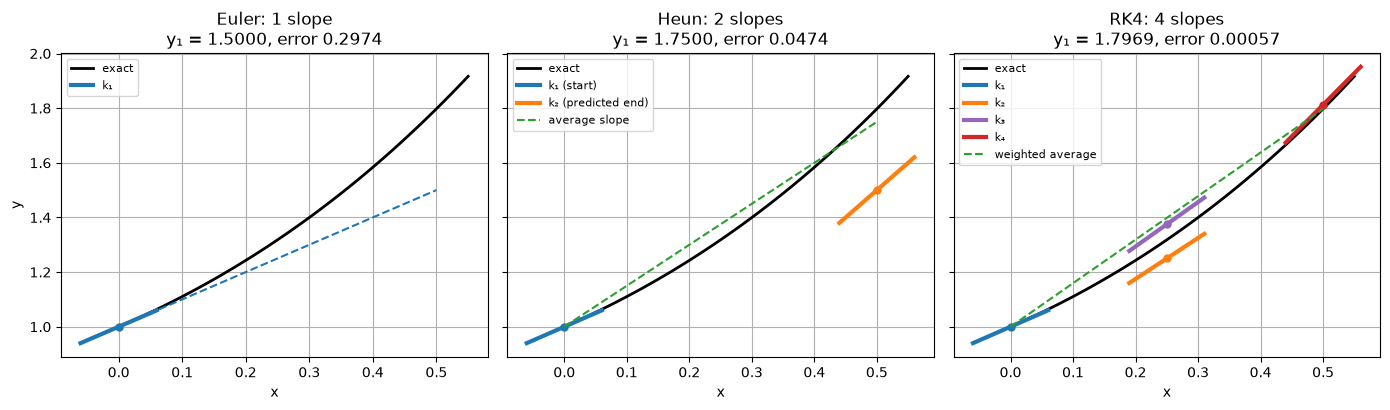

In [3]:
h, x0, y0 = 0.5, 0.0, 1.0
xf = np.linspace(0, 0.55, 100)

def slope_mark(ax, x, y, s, color, label=None):
    d = 0.06
    ax.plot([x - d, x + d], [y - d * s, y + d * s], color=color, lw=3, label=label)
    ax.plot(x, y, "o", color=color, ms=5)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax in axes:
    ax.plot(xf, exact(xf), "k", lw=2, label="exact")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")

# Euler
k1 = f(x0, y0)
y_e = y0 + h * k1
slope_mark(axes[0], x0, y0, k1, "C0", "k₁")
axes[0].plot([x0, h], [y0, y_e], "C0--")
axes[0].set_title(f"Euler: 1 slope\ny₁ = {y_e:.4f}, error {exact(h) - y_e:.4f}")

# Heun
k2 = f(x0 + h, y0 + h * k1)
y_h = y0 + h / 2 * (k1 + k2)
slope_mark(axes[1], x0, y0, k1, "C0", "k₁ (start)")
slope_mark(axes[1], x0 + h, y0 + h * k1, k2, "C1", "k₂ (predicted end)")
axes[1].plot([x0, h], [y0, y_h], "C2--", label="average slope")
axes[1].set_title(f"Heun: 2 slopes\ny₁ = {y_h:.4f}, error {exact(h) - y_h:.4f}")

# RK4
r1 = f(x0, y0)
r2 = f(x0 + h / 2, y0 + h / 2 * r1)
r3 = f(x0 + h / 2, y0 + h / 2 * r2)
r4 = f(x0 + h, y0 + h * r3)
y_r = y0 + h / 6 * (r1 + 2 * r2 + 2 * r3 + r4)
slope_mark(axes[2], x0, y0, r1, "C0", "k₁")
slope_mark(axes[2], x0 + h / 2, y0 + h / 2 * r1, r2, "C1", "k₂")
slope_mark(axes[2], x0 + h / 2, y0 + h / 2 * r2, r3, "C4", "k₃")
slope_mark(axes[2], x0 + h, y0 + h * r3, r4, "C3", "k₄")
axes[2].plot([x0, h], [y0, y_r], "C2--", label="weighted average")
axes[2].set_title(f"RK4: 4 slopes\ny₁ = {y_r:.4f}, error {exact(h) - y_r:.5f}")

for ax in axes:
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
print(f"exact y(0.5) = {exact(h):.6f}")

## 3.3 Why the order is what it is: matching the Taylor series

For the test problem, the exact solution after one step from $(0, 1)$ has the Taylor series

$$y(h) = 2e^{h} - h - 1 = 1 + h + h^2 + \frac{h^3}{3} + \frac{h^4}{12} + \frac{h^5}{60} + \cdots$$

Expanding each method's formula for one step, symbolically in $h$:

| Method | One step gives | First term missed (local error) | Predicted at $h=0.1$ | Actual |
|---|---|---|---|---|
| Euler | $1 + h$ | $h^2$ | $1.0 \times 10^{-2}$ | $1.03 \times 10^{-2}$ |
| Heun | $1 + h + h^2$ | $h^3/3$ | $3.3 \times 10^{-4}$ | $3.42 \times 10^{-4}$ |
| RK4 | $1 + h + h^2 + \frac{h^3}{3} + \frac{h^4}{12}$ | $h^5/60$ | $1.7 \times 10^{-7}$ | $1.69 \times 10^{-7}$ |

*(For RK4: $k_1 = 1$, $k_2 = 1 + h$, $k_3 = 1 + h + \tfrac{h^2}{2}$, $k_4 = 1 + 2h + h^2 + \tfrac{h^3}{2}$; substituting gives the expression in the table.)*

This is the real meaning of order: **a method of order $p$ reproduces the Taylor series of the true solution through the $h^p$ term.** The first term it misses, of size $h^{p+1}$, is the local error. Over $1/h$ steps these add up to a global error of $h^p$.

## 3.4 All three methods side by side

    x      Euler       Heun          RK4        Exact  |err| Eul |err| Heun  |err| RK4
  0.0   1.000000   1.000000   1.00000000   1.00000000   0.00e+00   0.00e+00   0.00e+00
  0.1   1.100000   1.110000   1.11034167   1.11034184   1.03e-02   3.42e-04   1.69e-07
  0.2   1.220000   1.242050   1.24280514   1.24280552   2.28e-02   7.56e-04   3.75e-07
  0.3   1.362000   1.398465   1.39971699   1.39971762   3.77e-02   1.25e-03   6.21e-07
  0.4   1.528200   1.581804   1.58364848   1.58364940   5.54e-02   1.85e-03   9.15e-07
  0.5   1.721020   1.794894   1.79744128   1.79744254   7.64e-02   2.55e-03   1.26e-06
  0.6   1.943122   2.040857   2.04423592   2.04423760   1.01e-01   3.38e-03   1.68e-06
  0.7   2.197434   2.323147   2.32750325   2.32750541   1.30e-01   4.36e-03   2.16e-06
  0.8   2.487178   2.645578   2.65107913   2.65108186   1.64e-01   5.50e-03   2.73e-06
  0.9   2.815895   3.012364   3.01920283   3.01920622   2.03e-01   6.84e-03   3.39e-06
  1.0   3.187485   3.428162   3.43655949   

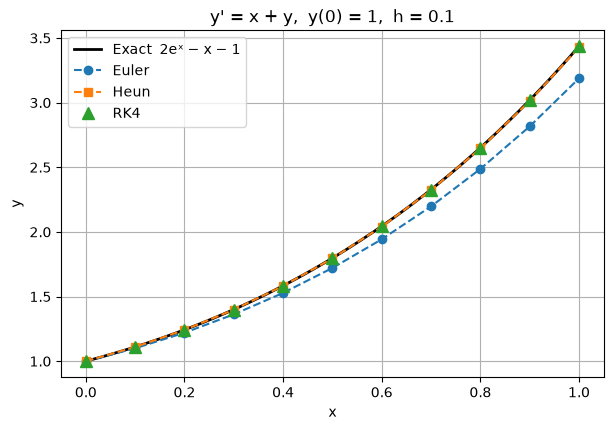

In [4]:
h, n = 0.1, 10
x, ye = euler(f, 0, 1, h, n)
_, yh = heun(f, 0, 1, h, n)
_, yr = rk4(f, 0, 1, h, n)
yx = exact(x)

print(f"{'x':>5} {'Euler':>10} {'Heun':>10} {'RK4':>12} {'Exact':>12} "
      f"{'|err| Eul':>10} {'|err| Heun':>10} {'|err| RK4':>10}")
for i in range(n + 1):
    print(f"{x[i]:5.1f} {ye[i]:10.6f} {yh[i]:10.6f} {yr[i]:12.8f} {yx[i]:12.8f} "
          f"{abs(ye[i]-yx[i]):10.2e} {abs(yh[i]-yx[i]):10.2e} {abs(yr[i]-yx[i]):10.2e}")

xf = np.linspace(0, 1, 200)
plt.plot(xf, exact(xf), "k", lw=2, label="Exact  2eˣ − x − 1")
plt.plot(x, ye, "o--", label="Euler")
plt.plot(x, yh, "s--", label="Heun")
plt.plot(x, yr, "^", ms=8, label="RK4")
plt.title("y' = x + y,  y(0) = 1,  h = 0.1")
plt.xlabel("x"); plt.ylabel("y"); plt.legend();

## 3.5 Butcher tableaux

Every explicit Runge–Kutta method with $s$ stages has the form

$$
\begin{aligned}
k_i &= f\Big(x_n + c_i h,\ \ y_n + h\sum_{j=1}^{i-1} a_{ij}\,k_j\Big), \qquad i = 1, \dots, s,\\
y_{n+1} &= y_n + h \sum_{i=1}^{s} b_i\,k_i,
\end{aligned}
$$

and is completely described by the numbers $c_i$, $a_{ij}$ and $b_i$. They are written in a **Butcher tableau**:

$$
\begin{array}{c|cccc}
c_1 & & & & \\
c_2 & a_{21} & & & \\
\vdots & \vdots & \ddots & & \\
c_s & a_{s1} & \cdots & a_{s,s-1} & \\ \hline
 & b_1 & \cdots & b_{s-1} & b_s
\end{array}
$$

* "Explicit" means the matrix $A = (a_{ij})$ is strictly lower triangular: stage $i$ uses only stages before it.
* Almost all methods satisfy $c_i = \sum_j a_{ij}$: each stage is evaluated at the $x$ value that its $y$ value corresponds to.
* The $b_i$ are the weights of the final average; they add up to 1.

$$
\underset{\text{Euler}}{\begin{array}{c|c} 0 & \\ \hline & 1 \end{array}}
\qquad
\underset{\text{Heun}}{\begin{array}{c|cc} 0 & & \\ 1 & 1 & \\ \hline & \tfrac12 & \tfrac12 \end{array}}
\qquad
\underset{\text{Midpoint}}{\begin{array}{c|cc} 0 & & \\ \tfrac12 & \tfrac12 & \\ \hline & 0 & 1 \end{array}}
\qquad
\underset{\text{Kutta's 3rd order}}{\begin{array}{c|ccc} 0 & & & \\ \tfrac12 & \tfrac12 & & \\ 1 & -1 & 2 & \\ \hline & \tfrac16 & \tfrac23 & \tfrac16 \end{array}}
$$

$$
\underset{\text{Classical RK4}}{\begin{array}{c|cccc} 0 & & & & \\ \tfrac12 & \tfrac12 & & & \\ \tfrac12 & 0 & \tfrac12 & & \\ 1 & 0 & 0 & 1 & \\ \hline & \tfrac16 & \tfrac13 & \tfrac13 & \tfrac16 \end{array}}
\qquad
\underset{\text{3/8 rule}}{\begin{array}{c|cccc} 0 & & & & \\ \tfrac13 & \tfrac13 & & & \\ \tfrac23 & -\tfrac13 & 1 & & \\ 1 & 1 & -1 & 1 & \\ \hline & \tfrac18 & \tfrac38 & \tfrac38 & \tfrac18 \end{array}}
$$

One function can now run **any** explicit Runge–Kutta method, given its tableau.

In [5]:
TABLEAUX = {
    "Euler":   dict(c=[0], A=[[0]], b=[1]),
    "Heun":    dict(c=[0, 1], A=[[0, 0], [1, 0]], b=[1/2, 1/2]),
    "Midpoint": dict(c=[0, 1/2], A=[[0, 0], [1/2, 0]], b=[0, 1]),
    "Ralston": dict(c=[0, 2/3], A=[[0, 0], [2/3, 0]], b=[1/4, 3/4]),
    "Kutta3":  dict(c=[0, 1/2, 1], A=[[0, 0, 0], [1/2, 0, 0], [-1, 2, 0]], b=[1/6, 2/3, 1/6]),
    "RK4":     dict(c=[0, 1/2, 1/2, 1],
                    A=[[0, 0, 0, 0], [1/2, 0, 0, 0], [0, 1/2, 0, 0], [0, 0, 1, 0]],
                    b=[1/6, 1/3, 1/3, 1/6]),
    "3/8 rule": dict(c=[0, 1/3, 2/3, 1],
                     A=[[0, 0, 0, 0], [1/3, 0, 0, 0], [-1/3, 1, 0, 0], [1, -1, 1, 0]],
                     b=[1/8, 3/8, 3/8, 1/8]),
}
TABLEAUX = {name: {k: np.array(v, dtype=float) for k, v in t.items()} for name, t in TABLEAUX.items()}


def explicit_rk(tableau, f, x0, y0, h, n):
    A, b, c = tableau["A"], tableau["b"], tableau["c"]
    s = len(b)
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k = np.zeros(s)
        for j in range(s):
            k[j] = f(x[i] + c[j] * h, y[i] + h * (A[j, :j] @ k[:j]))
        y[i + 1] = y[i] + h * (b @ k)
        x[i + 1] = x[i] + h
    return x, y


print("max difference between explicit_rk(RK4) and rk4:",
      np.max(np.abs(explicit_rk(TABLEAUX["RK4"], f, 0, 1, 0.1, 10)[1] - rk4(f, 0, 1, 0.1, 10)[1])))

max difference between explicit_rk(RK4) and rk4: 8.881784197001252e-16


## 3.6 Order conditions

Section 2.3 found the conditions for order 2 by matching Taylor series. Doing the same at higher order gives one condition for each distinct term ("elementary differential") in the Taylor series of the exact solution. In tableau notation, with $\mathbf{c} = (c_i)$, $\mathbf{1} = (1, \dots, 1)$ and powers of vectors taken componentwise:

| Order | New conditions |
|---|---|
| 1 | $\mathbf{b}\cdot\mathbf{1} = 1$ |
| 2 | $\mathbf{b}\cdot\mathbf{c} = \tfrac12$ |
| 3 | $\mathbf{b}\cdot\mathbf{c}^2 = \tfrac13$, $\quad \mathbf{b}\cdot A\mathbf{c} = \tfrac16$ |
| 4 | $\mathbf{b}\cdot\mathbf{c}^3 = \tfrac14$, $\quad \mathbf{b}\cdot(\mathbf{c} \ast A\mathbf{c}) = \tfrac18$, $\quad \mathbf{b}\cdot A\mathbf{c}^2 = \tfrac1{12}$, $\quad \mathbf{b}\cdot A^2\mathbf{c} = \tfrac1{24}$ |

(Here $\ast$ is the componentwise product.) A method has order $p$ if it satisfies every condition up to and including order $p$.

The code checks every tableau against these conditions.

In [6]:
def order_conditions(t):
    A, b, c = t["A"], t["b"], t["c"]
    one = np.ones_like(b)
    return {
        1: [(b @ one, 1)],
        2: [(b @ c, 1/2)],
        3: [(b @ c**2, 1/3), (b @ (A @ c), 1/6)],
        4: [(b @ c**3, 1/4), (b @ (c * (A @ c)), 1/8), (b @ (A @ c**2), 1/12), (b @ (A @ A @ c), 1/24)],
    }

def order_of(t):
    p = 0
    for order, conds in order_conditions(t).items():
        if all(abs(value - target) < 1e-12 for value, target in conds):
            p = order
        else:
            break
    return p

for name, t in TABLEAUX.items():
    print(f"{name:9s} stages = {len(t['b'])}   order (from conditions) = {order_of(t)}")

Euler     stages = 1   order (from conditions) = 1
Heun      stages = 2   order (from conditions) = 2
Midpoint  stages = 2   order (from conditions) = 2
Ralston   stages = 2   order (from conditions) = 2
Kutta3    stages = 3   order (from conditions) = 3
RK4       stages = 4   order (from conditions) = 4
3/8 rule  stages = 4   order (from conditions) = 4


**How fast the conditions multiply.** The number of order conditions grows quickly with the order:

| Order $p$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Conditions (total) | 1 | 2 | 4 | 8 | 17 | 37 | 85 | 200 |
| Minimum stages | 1 | 2 | 3 | 4 | 6 | 7 | 9 | 11 |

The second row is Butcher's **barrier** result: up to order 4 you need exactly $p$ stages, but beyond that the number of stages exceeds the order. Order 5 costs 6 evaluations per step. This is why RK4 is such a sweet spot: it is the highest order you get "at the price of the order".

## 3.7 Checking the orders numerically

The order conditions say what *should* happen. To confirm it, run each tableau on a **nonlinear** problem (as Section 2.4 showed, a linear test problem can hide differences between methods). Use the logistic equation

$$y' = y(1 - y), \qquad y(0) = 0.1, \qquad \text{exact solution } y = \frac{1}{1 + 9e^{-x}},$$

and estimate the order from errors at $x = 4$ with $h$ and $h/2$: $p \approx \log_2\big(E(h)/E(h/2)\big)$.

In [7]:
logistic = lambda x, y: y * (1 - y)
log_exact = lambda x: 1 / (1 + 9 * np.exp(-x))

print(f"{'method':9s} {'err h=0.2':>11} {'err h=0.1':>11} {'err h=0.05':>11} {'observed order':>15}")
for name, t in TABLEAUX.items():
    e = [abs(log_exact(4) - explicit_rk(t, logistic, 0, 0.1, h, round(4 / h))[1][-1]) for h in (0.2, 0.1, 0.05)]
    print(f"{name:9s} {e[0]:11.2e} {e[1]:11.2e} {e[2]:11.2e} {np.log2(e[1] / e[2]):15.2f}")

method      err h=0.2   err h=0.1  err h=0.05  observed order
Euler        4.22e-03    1.96e-03    9.45e-04            1.05
Heun         1.38e-03    3.46e-04    8.69e-05            1.99
Midpoint     4.59e-04    1.17e-04    2.94e-05            1.99
Ralston      7.64e-04    1.93e-04    4.86e-05            1.99
Kutta3       8.19e-06    1.11e-06    1.44e-07            2.94
RK4          1.54e-06    9.72e-08    6.11e-09            3.99
3/8 rule     1.12e-06    7.12e-08    4.49e-09            3.99


The observed orders match the order conditions: about 1 for Euler, 2 for the two-stage methods, 3 for Kutta's method and 4 for both four-stage methods.

## 3.8 Large steps on a smooth problem

High order pays off most when the solution is smooth and the interval is long. Take

$$y' = y\cos x, \qquad y(0) = 1, \qquad \text{exact solution } y = e^{\sin x}, \qquad 0 \le x \le 20,$$

with a **large** step $h = 0.5$ (only 40 steps over about three periods).

Euler  max |error| on [0, 20] = 2.32e+00   (40 f evaluations)
Heun   max |error| on [0, 20] = 2.22e-01   (80 f evaluations)
RK4    max |error| on [0, 20] = 2.20e-03   (160 f evaluations)


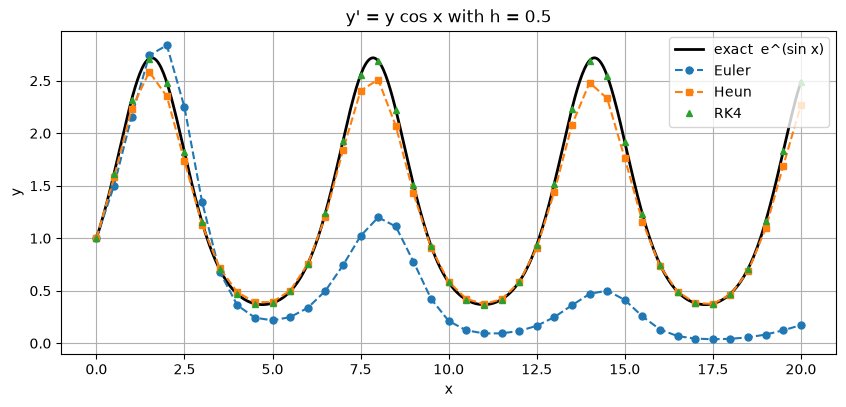

In [8]:
w = lambda x, y: y * np.cos(x)
w_exact = lambda x: np.exp(np.sin(x))
h, n = 0.5, 40
xf = np.linspace(0, 20, 600)
plt.figure(figsize=(10, 4.2))
plt.plot(xf, w_exact(xf), "k", lw=2, label="exact  e^(sin x)")
for name, method, style in [("Euler", euler, "o--"), ("Heun", heun, "s--"), ("RK4", rk4, "^")]:
    x, y = method(w, 0, 1, h, n)
    plt.plot(x, y, style, ms=5, label=name)
    print(f"{name:6s} max |error| on [0, 20] = {np.max(np.abs(y - w_exact(x))):.2e}   ({n * {'Euler': 1, 'Heun': 2, 'RK4': 4}[name]} f evaluations)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("y' = y cos x with h = 0.5"); plt.legend();

With only 40 steps, RK4 is visually indistinguishable from the exact solution, while Euler's solution has drifted far from it.

## 3.9 Summary

* RK4: four stages, order 4, Simpson's rule in disguise.
* A Butcher tableau $(A, \mathbf{b}, \mathbf{c})$ describes any Runge–Kutta method; one generic function can run them all.
* A method has order $p$ when its tableau satisfies all order conditions up to order $p$. Their number grows rapidly, and beyond order 4 more stages than the order are needed.

## Exercises

1. Take one RK4 step with $h = 0.1$ for $y' = y$, $y(0) = 1$. Show that the result is $1 + h + \frac{h^2}{2} + \frac{h^3}{6} + \frac{h^4}{24}$ and compare it with $e^{0.1}$.
2. Show by hand that Kutta's third-order method satisfies the four conditions for order 3.
3. Show that for $y' = \lambda y$ one RK4 step multiplies $y_n$ by $R(z) = 1 + z + \frac{z^2}{2} + \frac{z^3}{6} + \frac{z^4}{24}$ with $z = h\lambda$. (This polynomial reappears in [Section 5](05-stability-and-stiffness.ipynb).)
4. The tableau with $c = (0, 1)$, $a_{21} = 1$ and $b = (1, 0)$ is consistent ($\sum b_i = 1$). What is its order, and why is it a poor method?

**Answers**

1. $k_1 = 1$, $k_2 = 1 + \tfrac{h}{2}$, $k_3 = 1 + \tfrac{h}{2} + \tfrac{h^2}{4}$, $k_4 = 1 + h + \tfrac{h^2}{2} + \tfrac{h^3}{4}$. Substituting gives the Taylor polynomial: $1.1051708\overline{3}$ against $e^{0.1} = 1.1051709181$.
2. $\mathbf b\cdot\mathbf 1 = \tfrac16 + \tfrac23 + \tfrac16 = 1$; $\ \mathbf b\cdot\mathbf c = \tfrac23\cdot\tfrac12 + \tfrac16 = \tfrac12$; $\ \mathbf b\cdot\mathbf c^2 = \tfrac23\cdot\tfrac14 + \tfrac16 = \tfrac13$; $\ A\mathbf c = (0, 0, 2\cdot\tfrac12) = (0, 0, 1)$, so $\mathbf b\cdot A\mathbf c = \tfrac16$.
3. Same calculation as Exercise 1 with $\lambda y$ in place of $y$.
4. It is Euler's method with a wasted second stage: $\mathbf b\cdot\mathbf c = 0 \ne \tfrac12$, so order 1, at twice Euler's cost.

In [9]:
_, y = rk4(lambda x, y: y, 0, 1, 0.1, 1)
h = 0.1
print(f"1.  RK4 step = {y[1]:.10f},  Taylor polynomial = {1 + h + h**2/2 + h**3/6 + h**4/24:.10f},  e^0.1 = {np.exp(0.1):.10f}")
print(f"2.  Kutta3 order from conditions: {order_of(TABLEAUX['Kutta3'])}")
waste = {k: np.array(v, dtype=float) for k, v in dict(c=[0, 1], A=[[0, 0], [1, 0]], b=[1, 0]).items()}
print(f"4.  order from conditions: {order_of(waste)}")

1.  RK4 step = 1.1051708333,  Taylor polynomial = 1.1051708333,  e^0.1 = 1.1051709181
2.  Kutta3 order from conditions: 3
4.  order from conditions: 1
